# 07 - Self-training (semi-supervised learning)

*Suggested part for Itamar.*

Semi-supervised learning uses a small labeled set together with a large unlabeled one. In our data the natural
unlabeled set is the applications that are still pending, but they were all filed after the test years (2023 onward),
so using them to predict 2019-2022 would mean learning from the future. Instead we run the standard experiment from
class: keep the labels of only a small share of the training applications, hide the rest, and check whether
self-training on the hidden ones gets closer to a model that sees all the labels.

Self-training (sklearn `SelfTrainingClassifier`): train on the labeled rows, label the unlabeled rows the model is
confident about, add them to the training set, and repeat.

## Settings

In [1]:
LABELED_SHARES = [0.01, 0.05, 0.20]   # share of training labels that are kept
CONFIDENCE = 0.90                      # probability needed to add a pseudo-label
MAX_ITER = 10
RANDOM_STATE = 42

In [2]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.semi_supervised import SelfTrainingClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from lightgbm import LGBMClassifier

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from features import feature_groups
from modeling import make_preprocessor

FIG, OUT = ROOT / "figures", ROOT / "outputs"
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore")

feats = pd.read_parquet(ROOT / "data" / "processed" / "features.parquet")
numeric, categorical, text = feature_groups(feats.columns)
X_cols = numeric + categorical + [text]
train = feats[feats["is_train"]].reset_index(drop=True)
test = feats[~feats["is_train"]].reset_index(drop=True)

The preprocessing (scaling, one-hot, TF-IDF + SVD) doesn't use labels, so it is fit once on all training
applications, which is allowed in semi-supervised learning. A smaller LightGBM (200 trees) keeps the repeated
training fast. One caveat: the owner and attorney failure-rate features were computed from all training labels,
so they still carry some label information. A fully clean version would recompute them from the labeled rows only.

In [3]:
pre = make_preprocessor(numeric, categorical, text).fit(train[X_cols])
X_train, X_test = pre.transform(train[X_cols]), pre.transform(test[X_cols])
y_train, y_test = train["failed"].to_numpy(), test["failed"].to_numpy()

def base_model():
    return LGBMClassifier(n_estimators=200, num_leaves=63, learning_rate=0.05,
                          random_state=RANDOM_STATE, verbose=-1, n_jobs=-1)

def scores(model):
    p = model.predict_proba(X_test)[:, 1]
    return {"PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p)}

full = base_model().fit(X_train, y_train)
full_scores = scores(full)
print("All training labels:", {k: round(v, 3) for k, v in full_scores.items()})

All training labels: {'PR-AUC': 0.353, 'ROC-AUC': 0.73}


## 1. Labeled only vs. self-training

In [4]:
rows = []
for share in LABELED_SHARES:
    labeled_idx, _ = train_test_split(np.arange(len(y_train)), train_size=share,
                                      stratify=y_train, random_state=RANDOM_STATE)
    y_partial = np.full(len(y_train), -1)          # -1 = unlabeled for sklearn
    y_partial[labeled_idx] = y_train[labeled_idx]

    supervised = base_model().fit(X_train[labeled_idx], y_train[labeled_idx])
    rows.append({"labeled share": share, "method": "labeled only", **scores(supervised)})

    start = time.time()
    self_training = SelfTrainingClassifier(base_model(), threshold=CONFIDENCE, max_iter=MAX_ITER)
    self_training.fit(X_train, y_partial)
    added = (self_training.labeled_iter_ > 0).sum()
    pseudo = self_training.transduction_[self_training.labeled_iter_ > 0]
    rows.append({"labeled share": share, "method": "self-training", **scores(self_training),
                 "pseudo-labels added": added,
                 "share of added labeled 'failed'": pseudo.mean() if added else np.nan,
                 "minutes": round((time.time() - start) / 60, 1)})

st = pd.DataFrame(rows)
st.to_csv(OUT / "self_training_results.csv", index=False)
st.round(3)

,labeled share,method,PR-AUC,ROC-AUC,pseudo-labels added,share of added labeled 'failed',minutes
0,0.01,labeled only,0.246,0.653,NaN,NaN,NaN
1,0.01,self-training,0.240,0.649,178213.0,0.035,1.5
2,0.05,labeled only,0.300,0.695,NaN,NaN,NaN
3,0.05,self-training,0.292,0.691,169355.0,0.023,1.4
4,0.20,labeled only,0.327,0.714,NaN,NaN,NaN
5,0.20,self-training,0.322,0.711,130174.0,0.023,1.3


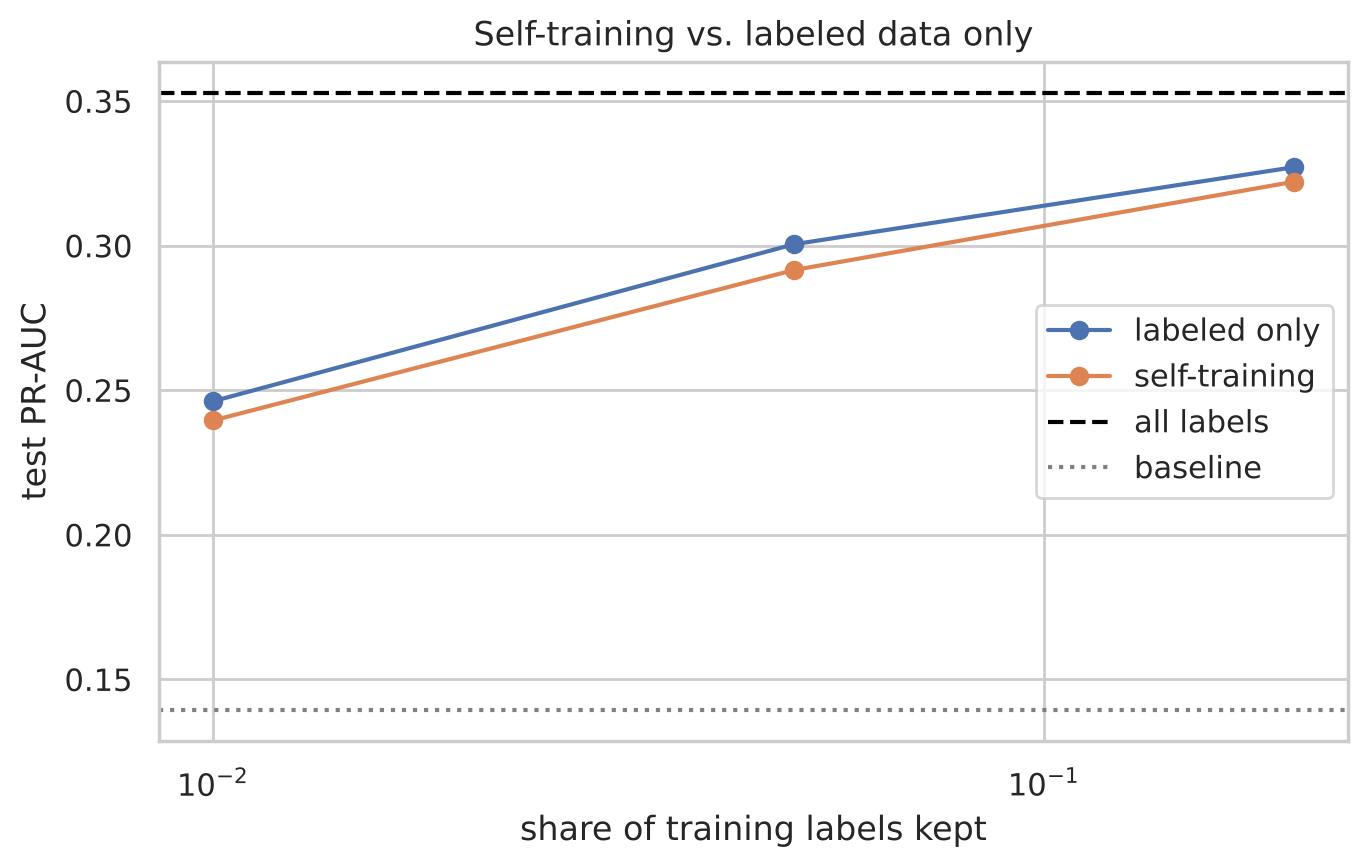

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for method, g in st.groupby("method"):
    ax.plot(g["labeled share"], g["PR-AUC"], marker="o", label=method)
ax.axhline(full_scores["PR-AUC"], color="black", ls="--", label="all labels")
ax.axhline(y_test.mean(), color="grey", ls=":", label="baseline")
ax.set_xscale("log")
ax.set(xlabel="share of training labels kept", ylabel="test PR-AUC", title="Self-training vs. labeled data only")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "self_training.png", dpi=120)
plt.show()

**Findings.** Self-training doesn't help here; it is slightly worse than training on the labeled rows alone at every
labeled share (for example PR-AUC 0.292 vs 0.300 with 5% of the labels). For reference, all labels give 0.353.

The table shows why. With a 0.9 confidence threshold, almost all unlabeled applications get a pseudo-label (130-178 thousand),
but only 2-4% of those pseudo-labels are "failed", compared with 15% in reality. The model is confident mostly about
registrations, so the added data pushes it further toward predicting "registered", and the class balance gets worse.

More labeled data clearly matters more: going from 1% to 20% of the labels raises PR-AUC from 0.25 to 0.33.
The ideas below (a balanced or k_best selection of pseudo-labels, or Label Propagation) are the natural next steps.

## Ideas to continue

- Recompute the owner and attorney failure rates from the labeled rows only, for a fully clean comparison.
- Try a lower confidence threshold, or `criterion="k_best"` to add a fixed number of pseudo-labels per round.
- Try Label Propagation (also from class) on a sample, and compare.